# BRUMA · 01 — Análisis exploratorio

PM2.5 en el Valle de Aburrá (2020-2025), red AMVA/SIATA publicada en datos.gov.co, y meteorología ERA5 (Open-Meteo).

Preguntas: ¿cómo cambia el PM2.5 en el año y en el día?, ¿dónde se concentra?, ¿qué pasa en los episodios de marzo y octubre?, ¿qué tan confiables son los datos? Todo lo que sigue son **asociaciones descriptivas**, no relaciones causales.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from bruma import config
IMG = ROOT / "docs" / "img"; IMG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
INK, ACCENT, TEAL, ORANGE, MUTED = "#1f2544", "#5b6cff", "#0f9f8f", "#f97316", "#8a93b5"
daily = pd.read_parquet(ROOT / "data/processed/daily_pm25.parquet")
hourly = pd.read_parquet(ROOT / "data/processed/hourly_pm25.parquet")
weather = pd.read_parquet(ROOT / "data/processed/daily_weather.parquet")
stations = pd.read_csv(ROOT / "data/processed/stations.csv")
names = dict(zip(stations.station, stations.nombre))
REF = [29493, 29509, 29511, 31379, 31854, 31856]  # estaciones con serie 2020-2025 consistente


## 1. Calidad de los datos

La regla más importante del pipeline: 14 estaciones publican en datos.gov.co valores que **no están en µg/m³** entre 2020 y 2023 (medianas mensuales de 100-2000). Desde 2024 coinciden exactamente con el archivo propio de SIATA. Abajo, la mediana mensual cruda de una estación de referencia y de una afectada.

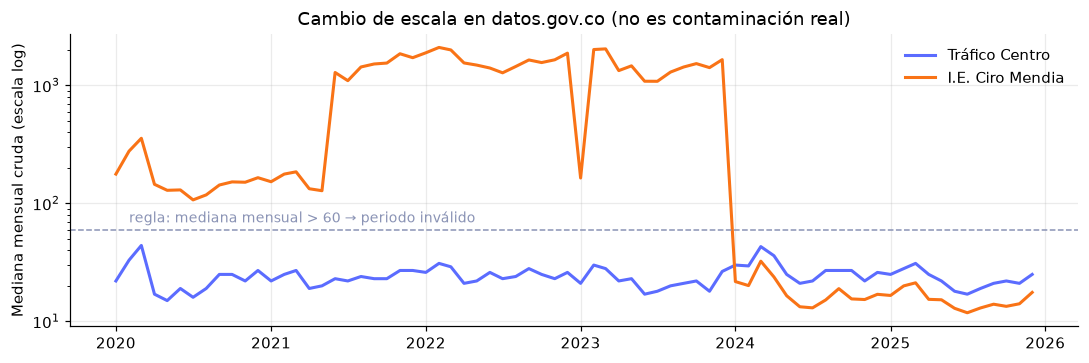

In [2]:
raw = {s: pd.read_csv(ROOT / f"data/raw/pm25/{s}.csv", parse_dates=["med_fecha_inicio"]) for s in (29509, 31364)}
fig, ax = plt.subplots(figsize=(10, 3.4))
for s, c in ((29509, ACCENT), (31364, ORANGE)):
    m = raw[s].set_index("med_fecha_inicio")["med_concentracion_estandar"].resample("MS").median()
    ax.plot(m.index, m.values, color=c, lw=2, label=names[s])
ax.set_yscale("log"); ax.set_ylabel("Mediana mensual cruda (escala log)")
ax.axhline(config.SCALE_MONTH_MEDIAN, color=MUTED, ls="--", lw=1)
ax.text(pd.Timestamp("2020-02-01"), config.SCALE_MONTH_MEDIAN * 1.15, "regla: mediana mensual > 60 → periodo inválido", color=MUTED, fontsize=9)
ax.legend(frameon=False); ax.set_title("Cambio de escala en datos.gov.co (no es contaminación real)")
fig.tight_layout(); fig.savefig(IMG / "calidad_datos.png", dpi=130, bbox_inches="tight")

In [3]:
q = json.loads((ROOT / "artifacts/data_quality.json").read_text(encoding="utf-8"))
pd.Series({k: v for k, v in q.items() if isinstance(v, int)}, name="filas/horas/días").to_frame()

,filas/horas/días
filas_crudas,924867
periodo_escala_inconsistente,409595
fuera_de_rango_o_no_numerico,409595
horas_duplicadas,0
sensor_pegado,6
picos_aislados,7
horas_validas,515259
dias_estacion_total,42767
dias_descartados_menos_de_18h,20833


In [4]:
pd.DataFrame({k: v.get("limpio", {}) | {"crudo_corr": v.get("crudo", {}).get("correlacion")} for k, v in q["contraste_siata"]["estaciones"].items()}).T

,horas_comparadas,correlacion,error_abs_medio,crudo_corr
CEN-TRAF,7991.0,1.0,0.000,1.0000
ITA-CJUS,8438.0,1.0,0.001,1.0000
EST-HOSP,8272.0,1.0,0.000,1.0000
MED-VILL,4610.0,1.0,0.004,0.0757
MED-ARAN,4800.0,1.0,0.004,0.0240
BEL-FEVE,4707.0,1.0,0.004,0.0566


In [5]:
valid = daily.dropna(subset=["pm25"])
cov = valid.groupby(["station", valid.date.dt.year]).size().unstack(fill_value=0)
cov.index = [names[s] for s in cov.index]
cov.sort_values(2020, ascending=False)

date,2020,2021,2022,2023,2024,2025
Hospital La Estrella,332,355,338,341,356,352
Casa Justicia,330,347,349,333,358,342
Tráfico Centro,328,332,342,341,347,345
I.E. Concejo Municipal,322,351,344,340,348,352
Tanques La Ye,321,352,349,0,91,0
Fiscalía Sector Caribe,247,343,340,340,327,339
Tanques EPM,3,346,336,345,344,354
Escuela Joaquín A.,0,0,0,0,324,347
I.E. Ciro Mendia,0,0,0,0,348,348
Torre Social,0,0,0,0,353,348


Resultado: 6 estaciones con serie consistente 2020-2025 (más La Ye hasta 2022) y 13 adicionales desde 2024. El modelo se entrena con lo que existe en cada momento; nada se imputa.

## 2. Estacionalidad anual

date,1,2,3,4,5,6,7,8,9,10,11,12
media,19.2,23.6,25.9,18.7,16.6,16.4,16.0,17.3,18.6,17.5,16.7,19.2
p10,14.3,16.9,17.2,12.3,12.4,11.8,12.3,12.5,13.2,12.5,12.1,14.8
p90,24.5,32.1,37.6,25.8,20.9,20.8,19.7,22.8,24.4,22.1,21.0,23.1


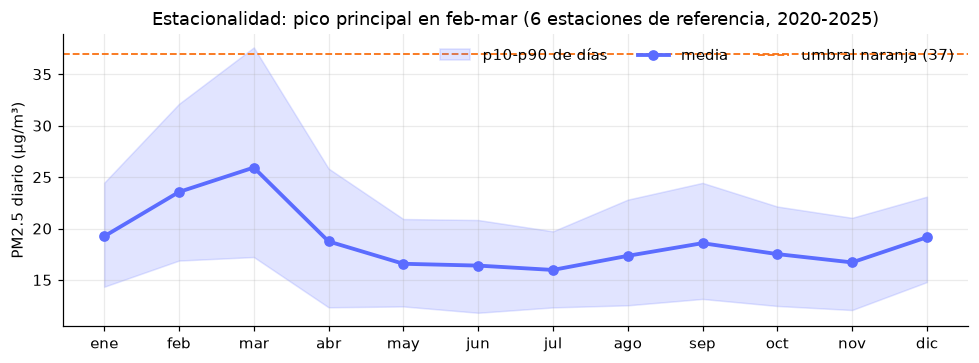

In [6]:
ref = valid[valid.station.isin(REF)]
vm = ref.groupby("date").pm25.mean()
clim = vm.groupby(vm.index.month).agg(["mean", lambda s: s.quantile(.1), lambda s: s.quantile(.9)])
clim.columns = ["media", "p10", "p90"]
meses = ["ene","feb","mar","abr","may","jun","jul","ago","sep","oct","nov","dic"]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.fill_between(clim.index, clim.p10, clim.p90, color=ACCENT, alpha=.18, label="p10-p90 de días")
ax.plot(clim.index, clim.media, color=ACCENT, lw=2.5, marker="o", label="media")
ax.axhline(config.ICA_NARANJA, color=ORANGE, ls="--", lw=1.2, label="umbral naranja (37)")
ax.set_xticks(range(1, 13), meses); ax.set_ylabel("PM2.5 diario (µg/m³)")
ax.set_title("Estacionalidad: pico principal en feb-mar (6 estaciones de referencia, 2020-2025)")
ax.legend(frameon=False, ncol=3, loc="upper right")
fig.tight_layout(); fig.savefig(IMG / "estacionalidad.png", dpi=130, bbox_inches="tight")
clim.round(1).T

Marzo es el mes más contaminado (25,9 µg/m³ de media, p90 por encima del umbral naranja), seguido de febrero. La "segunda temporada" de octubre que suele mencionarse apenas se ve en estos años: septiembre-octubre suben poco sobre julio, y diciembre-enero quedan incluso más altos. SIATA y el AMVA asocian el pico de marzo a la transición hacia la temporada de lluvias, con capas de mezcla bajas y nubosidad que atrapan los contaminantes; aquí solo lo observamos, no lo demostramos.

## 3. Ciclo diario

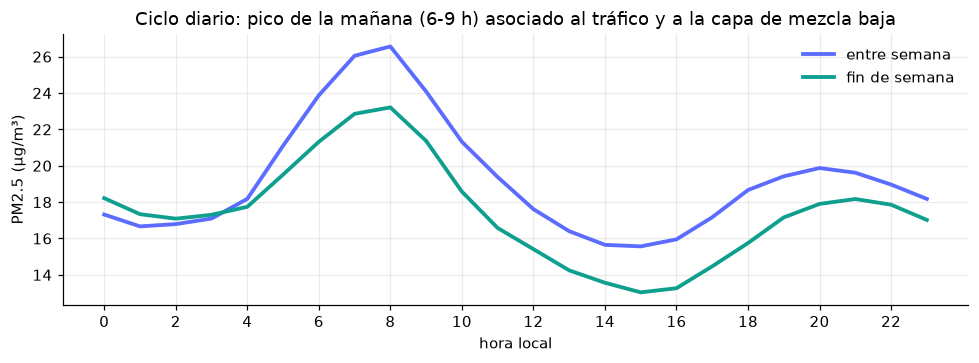

In [7]:
h = hourly[hourly.station.isin(REF)].dropna(subset=["pm25"]).copy()
h["hora"] = h.time.dt.hour; h["tipo"] = np.where(h.time.dt.day_of_week >= 5, "fin de semana", "entre semana")
prof = h.groupby(["tipo", "hora"]).pm25.mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(prof.index, prof["entre semana"], color=ACCENT, lw=2.5, label="entre semana")
ax.plot(prof.index, prof["fin de semana"], color=TEAL, lw=2.5, label="fin de semana")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hora local"); ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Ciclo diario: pico de la mañana (6-9 h) asociado al tráfico y a la capa de mezcla baja")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(IMG / "ciclo_diario.png", dpi=130, bbox_inches="tight")

In [8]:
dow = ref.groupby(ref.date.dt.day_of_week).pm25.mean()
dow.index = ["lun","mar","mié","jue","vie","sáb","dom"]; dow.round(1).to_frame("PM2.5 medio").T

,lun,mar,mié,jue,vie,sáb,dom
PM2.5 medio,17.5,19.0,19.6,19.4,19.7,18.9,15.8


## 4. Mapa de estaciones (2024-2025, todas con datos válidos)

,nombre,municipio,altitud,media,frac_naranja
station,,,,,
29509,Tráfico Centro,Medellín,1474,26.110,0.088
31371,Altavista,Medellín,1565,21.147,0.024
29493,Casa Justicia,Itagüí,1536,20.531,0.033
31369,I.E. Pedro Justo Botero,Medellín,1614,19.797,0.014
30732,Tanques La Ye,Medellín,1956,19.351,0.011
31854,Fiscalía Sector Caribe,Medellín,1458,18.104,0.009
31364,I.E. Ciro Mendia,Medellín,1545,17.773,0.017
31379,Hospital La Estrella,La Estrella,1765,17.005,0.020
31340,Escuela Joaquín A.,Caldas,1749,16.681,0.016


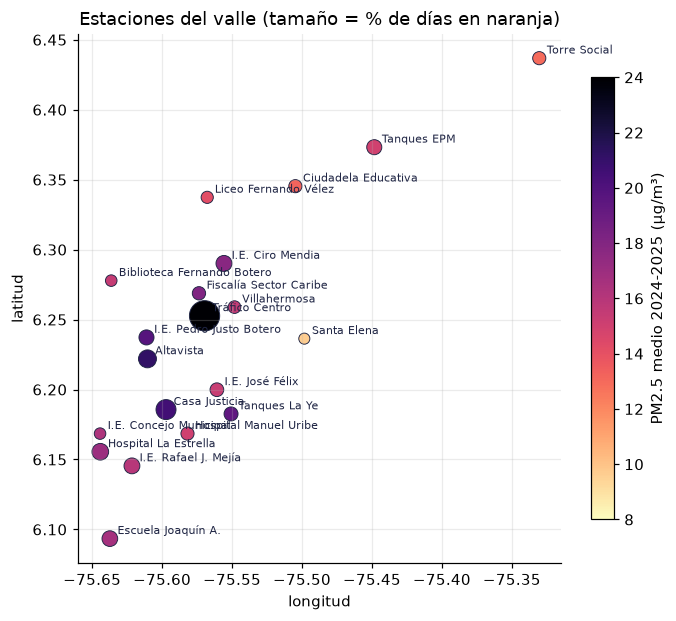

In [9]:
rec = valid[valid.date >= "2024-01-01"].groupby("station").pm25.agg(["mean", lambda s: (s > config.ICA_NARANJA).mean()])
rec.columns = ["media", "frac_naranja"]
st = stations.set_index("station").join(rec)
fig, ax = plt.subplots(figsize=(6.4, 7))
sc = ax.scatter(st.lon, st.lat, s=40 + st.frac_naranja * 4000, c=st.media, cmap="magma_r", edgecolor=INK, lw=.6, vmin=8, vmax=24)
for s, r in st.iterrows():
    ax.annotate(r.nombre, (r.lon, r.lat), fontsize=7, xytext=(5, 3), textcoords="offset points", color=INK)
plt.colorbar(sc, ax=ax, shrink=.6, label="PM2.5 medio 2024-2025 (µg/m³)")
ax.set_aspect("equal"); ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
ax.set_title("Estaciones del valle (tamaño = % de días en naranja)")
fig.tight_layout(); fig.savefig(IMG / "mapa_estaciones.png", dpi=130, bbox_inches="tight")
st[["nombre", "municipio", "altitud", "media", "frac_naranja"]].sort_values("media", ascending=False).round(3)

Tráfico Centro (centro de Medellín, junto a vías principales) es claramente la estación más alta y la que más días pasa en naranja (8,8 %), seguida de Altavista y Casa de Justicia (Itagüí). Santa Elena, a 2.580 m y fuera del cañón, registra la mitad del nivel del fondo del valle. La ubicación de cada sensor (cerca de tráfico o no) pesa tanto como la geografía.

## 5. Episodios de marzo y octubre

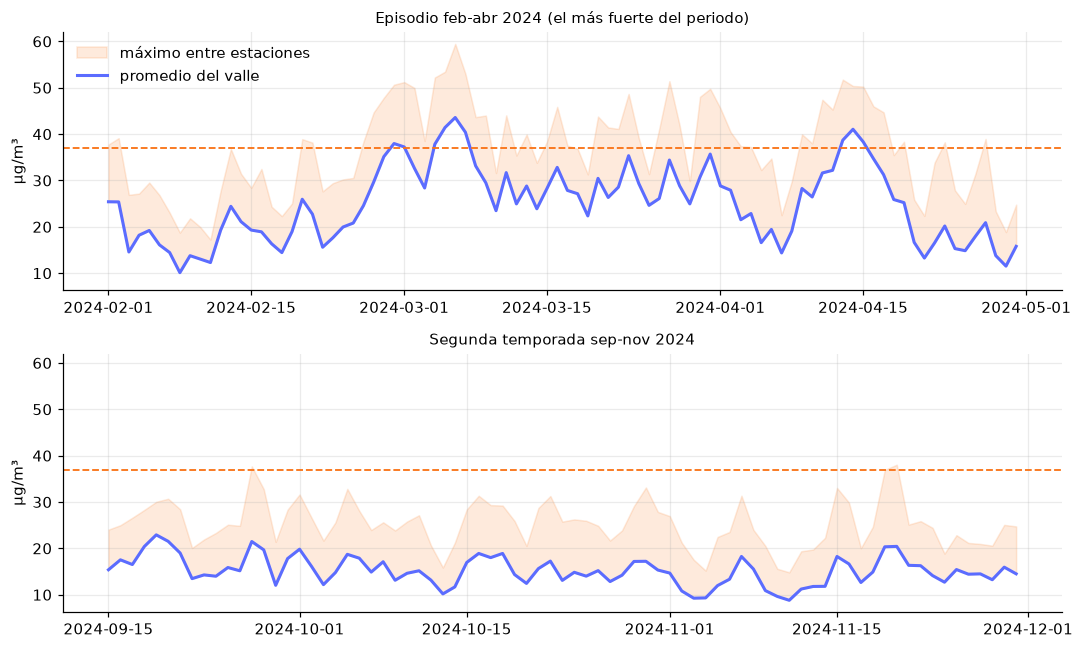

In [10]:
allv = valid.groupby("date").pm25.mean()
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharey=True)
for ax, (a, b, t) in zip(axes, [("2024-02-01", "2024-04-30", "Episodio feb-abr 2024 (el más fuerte del periodo)"),
                                  ("2024-09-15", "2024-11-30", "Segunda temporada sep-nov 2024")]):
    s = allv[a:b]; mx = valid[valid.date.between(a, b)].groupby("date").pm25.max()
    ax.fill_between(mx.index, s.reindex(mx.index), mx, color=ORANGE, alpha=.15, label="máximo entre estaciones")
    ax.plot(s.index, s.values, color=ACCENT, lw=2, label="promedio del valle")
    ax.axhline(config.ICA_NARANJA, color=ORANGE, ls="--", lw=1.2)
    ax.set_title(t, fontsize=10); ax.set_ylabel("µg/m³")
axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(IMG / "episodios.png", dpi=130, bbox_inches="tight")

In [11]:
ep = valid.assign(naranja=valid.pm25 > config.ICA_NARANJA)
ep.groupby([ep.date.dt.year, ep.date.dt.month]).naranja.sum().unstack(fill_value=0)

date,1,2,3,4,5,6,7,8,9,10,11,12
date,,,,,,,,,,,,
2020,0,14,16,3,0,0,0,0,0,1,0,0
2021,0,0,1,0,0,0,0,0,0,0,0,0
2022,0,5,13,0,0,1,0,0,0,1,0,0
2023,0,3,2,0,0,0,0,0,0,0,0,1
2024,10,23,110,57,1,0,0,2,3,0,1,3
2025,1,2,5,0,0,0,0,0,0,0,0,0


Los días en naranja se concentran en febrero-abril, con 2024 como el año más crítico (110 estación-días solo en marzo). En la segunda mitad del año los niveles suben poco y casi nunca cruzan 37 µg/m³ en el promedio de 24 h. Ojo: desde 2024 hay 19 estaciones válidas y antes solo 6-7, así que los conteos por año no son comparables directamente.

## 6. Meteorología asociada

,Spearman
pm25,1.00
blh_day,-0.04
blh_night,-0.17
precip_sum,0.04
rh_mean,0.03
wind_mean,-0.07
rad_sum,-0.06
cloud_mean,-0.04


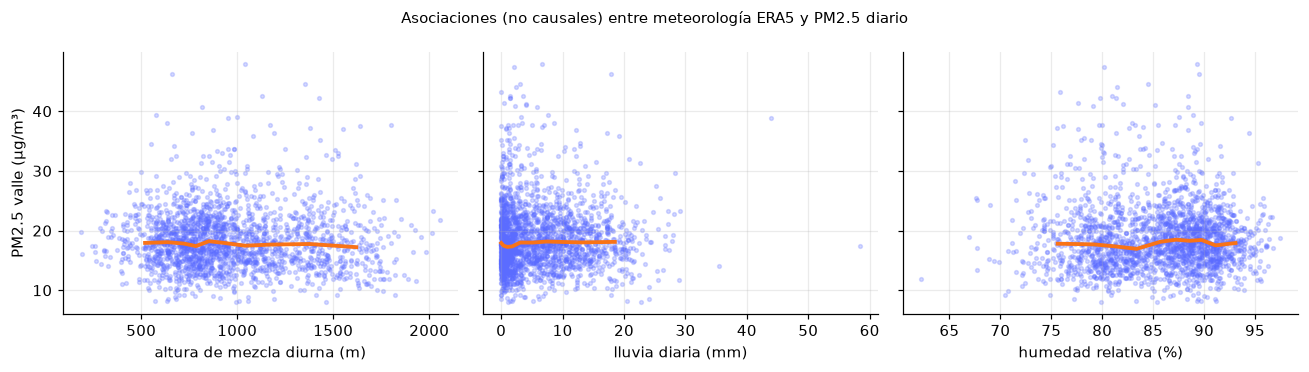

In [12]:
j = vm.to_frame("pm25").join(weather.set_index("date"))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (c, lab) in zip(axes, [("blh_day", "altura de mezcla diurna (m)"), ("precip_sum", "lluvia diaria (mm)"), ("rh_mean", "humedad relativa (%)")]):
    ax.scatter(j[c], j.pm25, s=6, alpha=.25, color=ACCENT)
    b = pd.qcut(j[c].rank(method="first"), 10); g = j.groupby(b, observed=True)[[c, "pm25"]].median()
    ax.plot(g[c], g.pm25, color=ORANGE, lw=2.5); ax.set_xlabel(lab)
axes[0].set_ylabel("PM2.5 valle (µg/m³)")
fig.suptitle("Asociaciones (no causales) entre meteorología ERA5 y PM2.5 diario", fontsize=10)
fig.tight_layout(); fig.savefig(IMG / "meteorologia.png", dpi=130, bbox_inches="tight")
j[["pm25", "blh_day", "blh_night", "precip_sum", "rh_mean", "wind_mean", "rad_sum", "cloud_mean"]].corr(method="spearman")["pm25"].round(2).to_frame("Spearman")

Las correlaciones con un único punto de reanálisis (~25 km) son muy débiles (|ρ| ≤ 0,17; la más fuerte es la altura de mezcla nocturna, negativa). Es probable que ERA5 no resuelva bien la meteorología de un valle de ~10 km de ancho. Esto anticipa un resultado del modelado: la meteorología del día objetivo aporta poco frente a la persistencia de la propia contaminación.

## 7. Autocorrelación: la base del pronóstico

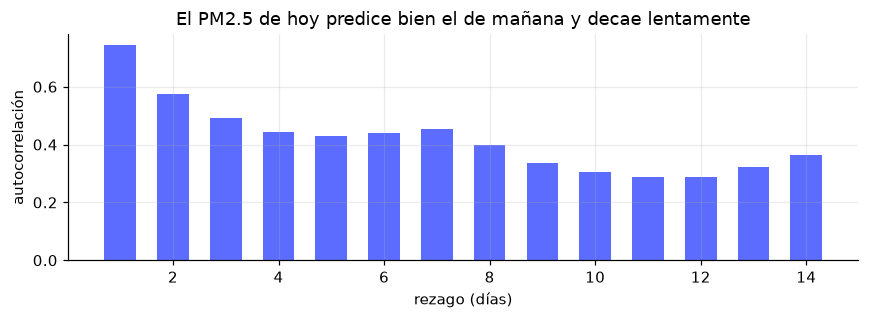

In [13]:
ac = {k: vm.autocorr(k) for k in range(1, 15)}
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(list(ac), list(ac.values()), color=ACCENT, width=.6)
ax.set_xlabel("rezago (días)"); ax.set_ylabel("autocorrelación"); ax.set_title("El PM2.5 de hoy predice bien el de mañana y decae lentamente")
fig.tight_layout()